# Tarea 2 · Parte 1 – Corpus y extracción

- **Fecha de extracción:** 25/10/2026
- **Fuentes y licencias:** Wikimedia Commons (dominio público, CC0, CC BY 2.0/3.0, CC BY-SA 3.0/4.0) para los 25 documentos y 12 entrevistas; OpenSLR 73 (CC BY-SA 4.0) para 6 clips leídos. Ningún archivo es de los usados en clase. Detalle por archivo en `datos/fuentes.csv`.
- **OCR:** PaddleOCR 3.7.0 · modelo PP-OCRv6 (detector + reconocedor, engine=transformers, GPU MPS)
- **ASR:** faster-whisper 1.2.1 · modelo `small` (Systran/faster-whisper-small, int8, CPU, VAD activado, idioma `es`)
- **Diarización:** WeSpeaker ResNet34 (pyannote) + clustering jerárquico (`voz.diarizar`)
- **Entorno:** proyecto uv (`pyproject.toml` + `uv.lock`), Python 3.12

In [1]:
import os, sys, time, json, hashlib, warnings, re, shutil
from pathlib import Path

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"   # antes de importar PaddleOCR
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"                # si una operación no existe en MPS, usa CPU
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
import soundfile as sf
import torch
import paddleocr, faster_whisper
from paddleocr import PaddleOCR
from PIL import Image

import voz
from voz import SR, Transcriptor, cargar_audio, diarizar, a_srt, a_texto, a_tabla, seudonimizar, tramos_de_voz

pio.renderers.default = "vscode+png"   # interactivo en VS Code y PNG para que se vea en GitHub

DATOS = Path("datos")
RAW_DOC, RAW_AUD = DATOS / "raw" / "documentos", DATOS / "raw" / "audio"
RAW_DOC.mkdir(parents=True, exist_ok=True); RAW_AUD.mkdir(parents=True, exist_ok=True)

print(f"PaddleOCR {paddleocr.__version__} · faster-whisper {faster_whisper.__version__} · PyTorch {torch.__version__}")
print("MPS disponible:", torch.backends.mps.is_available())


PaddleOCR 3.7.0 · faster-whisper 1.2.1 · PyTorch 2.14.1
MPS disponible: True


In [12]:
from urllib.parse import urlparse

API = "https://commons.wikimedia.org/w/api.php"
AGENTE = {"User-Agent": "tarea2-ds-python/2026 (https://github.com/jyauric/python-actividades)"}

def commons_api(**params):
    "Consulta la API de Wikimedia Commons con User-Agent y una pausa de cortesía."
    r = requests.get(API, params={"action": "query", "format": "json", **params}, headers=AGENTE, timeout=60)
    r.raise_for_status()
    time.sleep(1.5)
    return r.json()["query"]

def archivos_de_categoria(categoria, n=100):
    "Números de página (pageid) de los archivos de una categoría de Commons."
    q = commons_api(list="categorymembers", cmtitle=f"Category:{categoria}", cmtype="file", cmlimit=n)
    return [m["pageid"] for m in q["categorymembers"]]

CATEGORIAS = ["Banknotes of Peru", "Documents of Peru", "Posters of Peru",
              "Signs in Lima", "Street signs in Lima", "Baptism certificates of Peru"]
candidatos = sorted({pid for c in CATEGORIAS for pid in archivos_de_categoria(c)})
print(len(candidatos), "archivos candidatos")

244 archivos candidatos


In [13]:
def metadatos(pageids, ancho=None):
    "Licencia, autor, tamaño y enlace de descarga de cada archivo, según su página de Commons."
    filas = []
    for i in range(0, len(pageids), 20):
        extra = {"iiurlwidth": ancho} if ancho else {}       # ancho: pide una versión reducida de la imagen
        q = commons_api(pageids="|".join(map(str, pageids[i:i + 20])), prop="imageinfo",
                        iiprop="size|url|extmetadata", iiextmetadatafilter="LicenseShortName|Artist", **extra)
        for pg in q["pages"].values():
            ii = pg["imageinfo"][0]
            em = ii["extmetadata"]
            limpio = lambda k: re.sub(r"<[^>]+>", "", em.get(k, {}).get("value", "")).strip()
            filas.append({"pageid": pg["pageid"], "ancho": ii["width"], "alto": ii["height"],
                          "licencia": limpio("LicenseShortName"), "autor": limpio("Artist")[:60],
                          "url_descarga": ii.get("thumburl", ii["url"])})
    return pd.DataFrame(filas)

cand = metadatos(candidatos, ancho=1600)
LIBRES = r"Public domain|CC0|CC BY"                  # dominio público, CC0, CC BY y CC BY-SA
cand = cand[cand.licencia.str.contains(LIBRES)].reset_index(drop=True)
print(len(cand), "candidatos con licencia libre")
cand.licencia.value_counts()

244 candidatos con licencia libre


licencia
CC BY-SA 4.0     125
CC0               35
Public domain     31
CC BY-SA 2.0      20
CC BY 2.0         15
CC BY-SA 3.0      11
CC BY 3.0          3
CC BY 4.0          3
CC BY 3.0 de       1
Name: count, dtype: int64

### Selección de los 25 documentos

La búsqueda en 6 categorías de Wikimedia Commons devolvió 244 candidatos con licencia libre.
La preselección de 25 se hizo con apoyo del asistente de IA (Claude Code), con este criterio:

- 8 **impresos** nítidos, 8 **fotos** con ángulo, sombra o reflejos y 9 **manuscritos**;
- texto en español legible para una persona;
- ninguno de los documentos usados en clase.

Cada archivo se identifica por su número de página de Commons (`pageid`) y se cita con la URL `https://commons.wikimedia.org/?curid=…`, porque varios títulos contienen nombres de personas.
La licencia y el autor se toman de la API de Commons (no se escriben a mano), y la selección se verificó revisando las 25 imágenes.


In [17]:
SELECCION = {   # tipo → números de página de Commons (pageid)
    "impreso": [2121996,     # billete de 1 sol (s. XIX)
                2229021,     # billete de 5 soles (s. XIX)
                2263189,     # billete de 100 pesos (1867)
                2044186,     # billete de 40 centavos, Banco de Arequipa (1873)
                2284104,     # billete de 1 inca
                7279749,     # himno de Chanchamayo
                111181262,   # titular sobre Indecopi
                175594467],  # carta mecanografiada de la Presidencia (1956)
    "foto": [154062977, 154063152, 154063179,   # letreros con el antiguo nombre de la calle (Lima)
             124562195,      # panel informativo de una huaca
             150442442,      # cartel de rutas en la Panamericana Sur
             95621317,       # letrero del bosque El Olivar
             84154317,       # banner contra el dengue (Madre de Dios)
             153256484],     # hoja de servicios naval enmarcada, bajo vidrio
    "manuscrito": [160615606, 160615612, 160615607,   # Libro de Bautismos de Lampa (1655–1722, 1832, 1871)
                   15315035,     # recibo telegráfico de 1915 llenado a mano
                   67887441,     # partida de bautismo (s. XVIII)
                   190398555,    # partida de bautismo (1897)
                   131142697,    # afiches escritos a mano por estudiantes
                   131142702,    # carteles escritos a mano por estudiantes
                   5100641],     # tarjeta de circulación de 1921 llenada a mano
}
inventario = pd.DataFrame([(t, pid) for t, lista in SELECCION.items() for pid in lista], columns=["tipo", "pageid"])
inventario = inventario.merge(cand[["pageid", "licencia", "autor", "url_descarga"]], on="pageid", how="left")
assert inventario.licencia.notna().all(), "Hay un archivo elegido que no está entre los candidatos con licencia libre"
# 🔒 En dos archivos de dominio público, el campo «autor» de Commons repite datos del propio documento
# (la persona inscrita o su familia): se reemplaza por la institución que emitió el documento.
AUTOR_CORREGIDO = {190398555: "Parroquia de San Clemente de Pisco (registro parroquial)",
                   5100641: "Prefectura de Lima (tarjeta oficial de 1921)"}
inventario["autor"] = inventario.pageid.map(AUTOR_CORREGIDO).fillna(inventario.autor)
inventario["fuente_url"] = "https://commons.wikimedia.org/?curid=" + inventario.pageid.astype(str)
inventario.insert(0, "id", [f"doc_{i:03d}" for i in range(1, len(inventario) + 1)])   # ids neutrales
COLS_INV = ["id", "tipo", "pageid", "licencia", "autor", "fuente_url"]               # sin url_descarga: lleva el título
inventario[COLS_INV].to_csv(DATOS / "inventario_documentos.csv", index=False)
inventario.tipo.value_counts()          # 8 impreso, 8 foto, 9 manuscrito

tipo
manuscrito    9
impreso       8
foto          8
Name: count, dtype: int64

In [ ]:
from IPython.display import HTML

HTML(inventario.assign(imagen=inventario.url_descarga.map(lambda u: f'<img src="{u}" width="160">'))
     [["id", "tipo", "imagen", "licencia"]].to_html(escape=False, index=False))

In [19]:
def descargar(url, destino):
    "Baja un archivo de Wikimedia Commons. Si ya está en disco, no hace nada."
    if not destino.exists():
        r = requests.get(url, headers=AGENTE, timeout=120)
        r.raise_for_status()
        destino.write_bytes(r.content)
        time.sleep(1.5)                      # cortesía con el servidor (1 a 2 s)
    return destino

inventario["archivo"] = [str(descargar(f.url_descarga, RAW_DOC / f"{f.id}{Path(urlparse(f.url_descarga).path).suffix.lower()}"))
                         for f in inventario.itertuples()]

### La GPU de tu Mac

PaddleOCR nació sobre **PaddlePaddle**, el framework de aprendizaje profundo de Baidu, y
PaddlePaddle en una Mac **solo usa la CPU**. Desde la versión 3.5, PaddleOCR puede ejecutar
los mismos modelos con **PyTorch** (`engine="transformers"`), y PyTorch sí sabe hablar con la
GPU de los chips de Apple a través de **MPS** (*Metal Performance Shaders*).

Primero averiguamos qué tiene esta máquina:

In [20]:
if torch.backends.mps.is_available():
    DISPOSITIVO = "mps"       # GPU de un chip Apple (M1 en adelante)
elif torch.cuda.is_available():
    DISPOSITIVO = "cuda"      # GPU NVIDIA
else:
    DISPOSITIVO = "cpu"

print(f"PaddleOCR {paddleocr.__version__} · PyTorch {torch.__version__}")
print(f"Dispositivo elegido: {DISPOSITIVO}")

PaddleOCR 3.7.0 · PyTorch 2.14.1
Dispositivo elegido: mps


In [21]:
def redes(obj, _prof=0, _vistos=None):
    "Busca, dentro de un modelo de PaddleOCR, las redes neuronales de PyTorch."
    _vistos = set() if _vistos is None else _vistos
    if id(obj) in _vistos or _prof > 7:
        return
    _vistos.add(id(obj))
    if isinstance(obj, torch.nn.Module):
        yield obj
        return
    for hijo in (vars(obj).values() if hasattr(obj, "__dict__") else []):
        for x in (hijo.values() if isinstance(hijo, dict) else [hijo]):
            if not isinstance(x, (str, int, float, bool, type(None), list, tuple, set)):
                yield from redes(x, _prof + 1, _vistos)


PAPELES = {"Layout": "detector de bloques", "Det": "detector de texto",
           "Rec": "reconocedor de texto", "VL": "modelo de visión-lenguaje"}


def a_gpu(modelo, dispositivo=DISPOSITIVO):
    "Mueve todas las redes del modelo al dispositivo elegido e informa qué movió."
    for red in redes(modelo):
        red.to(dispositivo)
        clase = type(red).__name__
        papel = next((p for pista, p in PAPELES.items() if pista in clase), clase)
        millones = sum(p.numel() for p in red.parameters()) / 1e6
        print(f"  {papel:<26} {millones:6.1f} millones de parámetros → {dispositivo}")
    return modelo

In [22]:
def leer(ruta, modelo=None):
    "OCR de una imagen. Devuelve una tabla con una fila por cada línea de texto."
    r = (ocr if modelo is None else modelo).predict(str(ruta))[0]
    cajas = np.asarray(r["rec_boxes"]).reshape(-1, 4)          # x0, y0, x1, y1 de cada línea
    return pd.DataFrame({
        "texto": r["rec_texts"],
        "confianza": np.round(r["rec_scores"], 3),
        "x0": cajas[:, 0], "y0": cajas[:, 1], "x1": cajas[:, 2], "y1": cajas[:, 3],
    })

In [23]:
OPCIONES = dict(
    use_doc_orientation_classify=False,   # no girar la página completa
    use_doc_unwarping=False,              # no "planchar" hojas dobladas
    use_textline_orientation=False,       # no girar cada línea
)
ocr = PaddleOCR(engine="transformers", **OPCIONES)   # PyTorch, para poder usar la GPU de la Mac
a_gpu(ocr, "mps")
MODELO_OCR = f"PaddleOCR {paddleocr.__version__} PP-OCRv6 (engine=transformers, MPS, sin orientación ni unwarping)"

CRUDO = RAW_DOC / "crudo"; CRUDO.mkdir(exist_ok=True)
filas = []
for f in inventario.itertuples():
    r = ocr.predict(str(f.archivo))[0]
    r.save_to_json(str(CRUDO))            # respaldo crudo: textos, cajas y confianzas
    r.save_to_img(str(CRUDO))             # imagen con las cajas detectadas
    filas.append({
        "id": f.id, "archivo": f.archivo, "tipo": f.tipo,
        "fuente": f"{f.fuente_url} ({f.licencia})",
        "texto_ocr": " ".join(r["rec_texts"]),
        "modelo_ocr": MODELO_OCR,
        "n_lineas": len(r["rec_texts"]),
        "confianza_mediana": float(np.median(r["rec_scores"])) if len(r["rec_scores"]) else 0.0,
    })
documentos = pd.DataFrame(filas)
documentos.groupby("tipo")[["n_lineas", "confianza_mediana"]].median()

Creating model: ('PP-OCRv6_medium_det', None, 'transformers')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/josselinyauri/.paddlex/official_models/PP-OCRv6_medium_det_safetensors`.
W1025 22:29:47.434000 9855 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 350/350 [00:00<00:00, 11508.63it/s]
Creating model: ('PP-OCRv6_medium_rec', None, 'transformers')
Model files already exist. Using cached files. To redownload, please delete the directory manually: `/Users/josselinyauri/.paddlex/official_models/PP-OCRv6_medium_rec_safetensors`.
Loading weights: 100%|██████████| 269/269 [00:00<00:00, 12117.71it/s]


  detector de texto            22.0 millones de parámetros → mps
  reconocedor de texto         19.1 millones de parámetros → mps


Connecting to https://paddle-model-ecology.bj.bcebos.com/paddlex/PaddleX3.0/fonts/simfang.ttf ...
[==================================================] 100.00%


,n_lineas,confianza_mediana
tipo,,
foto,11.5,0.966088
impreso,16.0,0.939521
manuscrito,16.0,0.851281


In [24]:
import datos, io, random, zipfile

def buscar_archivos(texto, n=40):
    "Busca archivos en Commons (espacio de nombres 6 = archivos) y devuelve sus pageid."
    q = commons_api(list="search", srsearch=texto, srnamespace=6, srlimit=n)
    return [m["pageid"] for m in q["search"]]

BUSQUEDAS = ["filetype:audio entrevista Perú", "filetype:audio Lima entrevista", "filetype:audio Wikimedia Perú entrevista"]
cand_audio = metadatos(sorted({pid for b in BUSQUEDAS for pid in buscar_archivos(b)}))
print(len(cand_audio), "audios candidatos")

49 audios candidatos


### Selección de las 12 entrevistas

La búsqueda en Wikimedia Commons («entrevista Perú», «Lima entrevista», «Wikimedia Perú entrevista») devolvió los candidatos de arriba. La preselección se hizo con apoyo del asistente de IA (Claude Code), con este criterio:

- español hablado en el Perú y licencia libre (todas CC BY-SA 4.0);
- se excluyen las entrevistas en quechua (Shansha), las de otros países, las usadas en clase (El Agustino y la conferencia de Fenmucarinap) y la de un ciudadano venezolano;
- quedan 12 entrevistas (~25 min), identificadas por su `pageid` y una clave neutral `cmNN`, porque varios títulos contienen nombres de personas.

In [25]:
AUDIOS_COMMONS = {   # clave neutral → número de página de Commons (pageid)
    "cm01": 119950449,   # entrevista en una marcha (Lima)
    "cm02": 121363454,   # entrevista registrada por estudiante de la UNMSM (1)
    "cm03": 121363453,   # ídem (2)
    "cm04": 121363455,   # ídem (3)
    "cm05": 121363456,   # ídem (4)
    "cm06": 121219891,   # conferencia de prensa de una organización de mujeres indígenas
    "cm07": 149445104,   # fiesta patronal de Tayta Palli (Chuyas)
    "cm08": 149433723,   # celebración de la Santísima Trinidad (Chuyas)
    "cm09": 149433722,   # celebración de la Santísima Trinidad (Pomabamba)
    "cm10": 133964620,   # entrevista en una marcha (UNMSM)
    "cm11": 133964621,   # entrevistas en una marcha (UNMSM)
    "cm12": 119262664,   # minientrevistas en el repechaje Perú–Australia
}
atribucion = (pd.DataFrame(AUDIOS_COMMONS.items(), columns=["clave", "pageid"])
              .merge(cand_audio[["pageid", "licencia", "autor", "url_descarga"]], on="pageid", how="left"))
assert atribucion.licencia.notna().all(), "Hay un audio elegido que no salió en la búsqueda"

ENT = RAW_AUD / "entrevistas"; ENT.mkdir(parents=True, exist_ok=True)
atribucion["archivo"] = [f"{c}{Path(urlparse(u).path).suffix.lower()}" for c, u in zip(atribucion.clave, atribucion.url_descarga)]
for f in atribucion.itertuples():
    descargar(f.url_descarga, ENT / f.archivo)
atribucion["fuente"] = "https://commons.wikimedia.org/?curid=" + atribucion.pageid.astype(str)
atribucion.drop(columns="url_descarga").to_csv(ENT / "atribucion.csv", index=False)   # estilo Sesión 13
atribucion[["clave", "pageid", "licencia", "autor"]]

,clave,pageid,licencia,autor
0,cm01,119950449,CC BY-SA 4.0,Joaquin Canales
1,cm02,121363454,CC BY-SA 4.0,Gianpier Yair Venegas Ambia
2,cm03,121363453,CC BY-SA 4.0,Gianpier Yair Venegas Ambia
3,cm04,121363455,CC BY-SA 4.0,Gianpier Yair Venegas Ambia
4,cm05,121363456,CC BY-SA 4.0,Gianpier Yair Venegas Ambia
5,cm06,121219891,CC BY-SA 4.0,QM Keen
6,cm07,149445104,CC BY-SA 4.0,GFSA01
7,cm08,149433723,CC BY-SA 4.0,Rashelley Perez
8,cm09,149433722,CC BY-SA 4.0,Rashelley Perez
9,cm10,133964620,CC BY-SA 4.0,Hellloff233


In [28]:
datos.OPENSLR73 = "https://openslr.trmal.net/resources/73/es_pe_{sexo}.zip"   # espejo de OpenSLR (el principal no respondió)
def clips_openslr73(sexo, n_clips, frases_por_clip=18, semilla=7, pausa=0.5):
    "Une frases de un mismo hablante peruano en clips de ~1,5 min. Guarda el WAV y su metadato."
    z = zipfile.ZipFile(datos.ZipRemoto(datos.OPENSLR73.format(sexo=sexo)))
    lineas = z.read("line_index.tsv").decode("utf-8").strip().splitlines()
    tabla = pd.DataFrame([l.split("\t") for l in lineas], columns=["id", "texto"])
    tabla["hablante"] = tabla["id"].str.rsplit("_", n=1).str[0]
    conteo = tabla["hablante"].value_counts()
    hablantes = sorted(conteo[conteo >= frases_por_clip].index)
    random.Random(semilla).shuffle(hablantes)
    filas = []
    for h in hablantes[:n_clips]:
        sel = tabla[tabla["hablante"] == h].head(frases_por_clip)
        partes = []
        for f in sel.itertuples():
            x, sr = sf.read(io.BytesIO(z.read(f"{f.id}.wav")), dtype="float32")
            partes += [cargar_audio(x, sr), np.zeros(int(pausa * SR), dtype=np.float32)]
        ruta = RAW_AUD / f"openslr73_{h}.wav"
        sf.write(ruta, np.concatenate(partes), SR)
        filas.append({"origen": ruta.name, "hablante_fuente": h, "sexo": sexo,
                      "fuente_url": "https://www.openslr.org/73/", "licencia": "CC BY-SA 4.0",
                      "texto_fuente": " ".join(sel.texto)})   # ⚡ texto oficial de las frases, en el mismo orden
    return pd.DataFrame(filas)

slr = pd.concat([clips_openslr73("female", 3, semilla=2026), clips_openslr73("male", 3, semilla=2026)], ignore_index=True)

In [29]:
LARGAS = {"cm02", "cm05", "cm06"}        # más de 2 min
origenes = []
for f in atribucion.itertuples():
    ruta = ENT / f.archivo
    if f.clave not in LARGAS:
        origenes.append(ruta)
        continue
    x = cargar_audio(ruta)
    for k, a in enumerate(range(0, len(x), 60 * SR), start=1):
        if len(x[a:a + 60 * SR]) >= 15 * SR:
            tramo = ENT / f"{f.clave}__p{k:02d}.wav"
            sf.write(tramo, x[a:a + 60 * SR], SR)
            origenes.append(tramo)
origenes += sorted(RAW_AUD.glob("openslr73_*.wav"))

audios = pd.DataFrame({"origen": [str(o) for o in origenes]})
audios["id"] = [f"clip_{i:03d}" for i in range(1, len(audios) + 1)]
audios["archivo"] = [str(RAW_AUD / f"{i}{Path(o).suffix}") for i, o in zip(audios.id, audios.origen)]
for o, d in zip(audios.origen, audios.archivo):
    if not Path(d).exists():
        shutil.copy(o, d)

def fuente_de(origen):
    "URL y licencia de cada audio; los tramos heredan la de su entrevista."
    clave = Path(origen).stem.split("__")[0]
    if clave in set(atribucion.clave):
        fila = atribucion.set_index("clave").loc[clave]
        return fila.fuente, fila.licencia
    return "https://www.openslr.org/73/", "CC BY-SA 4.0"

audios[["fuente_url", "licencia"]] = [fuente_de(o) for o in audios.origen]
audios["duracion_seg"] = [round(len(cargar_audio(r)) / SR, 1) for r in audios["archivo"]]
audios[["id", "origen"]].to_csv(RAW_AUD / "mapa_ids.csv", index=False)   # correspondencia privada (no se versiona)
print(f"{len(audios)} clips · {audios.duracion_seg.sum() / 60:.1f} minutos")

31 clips · 36.0 minutos


In [30]:
BORRADOR = DATOS / "raw" / "referencias_borrador"; BORRADOR.mkdir(parents=True, exist_ok=True)
texto_slr = dict(zip(slr.origen, slr.texto_fuente))
for f in audios.itertuples():
    texto = texto_slr.get(Path(f.origen).name)
    if texto:
        (BORRADOR / f"{f.id}.txt").write_text(texto, encoding="utf-8")
print(len(list(BORRADOR.glob("clip_*.txt"))), "clips de OpenSLR con borrador de referencia")

6 clips de OpenSLR con borrador de referencia


In [31]:
voz.MODELOS["faster-whisper"]["hf"] = "small"   # ⚡ small (ya en caché) en vez de large-v3-turbo: ~3 veces más rápido
asr = Transcriptor("faster-whisper")            # faster-whisper en CTranslate2, int8 en CPU (VAD incluido)
MODELO_ASR = "faster-whisper small (int8, CPU, VAD on, beam=5)"
SALIDAS = RAW_AUD / "salidas"; SALIDAS.mkdir(exist_ok=True)

def con_marcas(segmentos):
    "Une turnos seguidos del mismo hablante y los marca como [HABLANTE_1], [HABLANTE_2]..."
    turnos = []
    for s in segmentos:
        marca = f"[HABLANTE_{s.hablante[1:]}]" if s.hablante else ""
        if turnos and turnos[-1][0] == marca:
            turnos[-1][1].append(s.texto)
        else:
            turnos.append([marca, [s.texto]])
    return " ".join(f"{m} {' '.join(t)}".strip() for m, t in turnos)

filas = []
for f in audios.itertuples():
    x = cargar_audio(f.archivo)
    t0 = time.perf_counter()
    segs = asr.segmentos(x, idioma="es")
    # OpenSLR: un solo lector por construcción; en las entrevistas, el número lo decide el umbral
    segs = diarizar(x, segs, n_hablantes=1 if "openslr73" in f.origen else None)
    n_hab = len({s.hablante for s in segs}) if segs else 0
    (SALIDAS / f"{f.id}.srt").write_text(a_srt(segs), encoding="utf-8")
    (SALIDAS / f"{f.id}.txt").write_text(a_texto(segs), encoding="utf-8")
    a_tabla(segs).to_csv(SALIDAS / f"{f.id}.csv", index=False)
    filas.append({"id": f.id, "archivo_audio": f.archivo, "duracion_seg": f.duracion_seg,
                  "idioma": "es", "texto_asr": con_marcas(segs) if n_hab > 1 else " ".join(s.texto for s in segs),
                  "modelo_asr": MODELO_ASR, "n_hablantes": n_hab,
                  "segundos_proceso": round(time.perf_counter() - t0, 1)})
    print(f"{f.id}: {f.duracion_seg:.0f} s de audio, {n_hab} hablante(s), {filas[-1]['segundos_proceso']} s")
transcripciones = pd.DataFrame(filas)

clip_001: 54 s de audio, 11 hablante(s), 26.5 s
clip_002: 60 s de audio, 2 hablante(s), 10.9 s
clip_003: 60 s de audio, 2 hablante(s), 9.1 s
clip_004: 60 s de audio, 2 hablante(s), 9.2 s
clip_005: 16 s de audio, 2 hablante(s), 3.0 s
clip_006: 96 s de audio, 2 hablante(s), 11.9 s
clip_007: 77 s de audio, 3 hablante(s), 13.6 s
clip_008: 60 s de audio, 3 hablante(s), 9.1 s
clip_009: 60 s de audio, 1 hablante(s), 6.3 s
clip_010: 44 s de audio, 1 hablante(s), 6.1 s
clip_011: 60 s de audio, 3 hablante(s), 8.1 s
clip_012: 60 s de audio, 2 hablante(s), 8.1 s
clip_013: 60 s de audio, 2 hablante(s), 7.8 s
clip_014: 60 s de audio, 1 hablante(s), 7.6 s
clip_015: 60 s de audio, 1 hablante(s), 7.1 s
clip_016: 60 s de audio, 1 hablante(s), 7.3 s
clip_017: 60 s de audio, 1 hablante(s), 7.5 s
clip_018: 60 s de audio, 2 hablante(s), 9.0 s
clip_019: 18 s de audio, 1 hablante(s), 2.8 s
clip_020: 39 s de audio, 1 hablante(s), 5.1 s
clip_021: 98 s de audio, 2 hablante(s), 2.2 s
clip_022: 82 s de audio, 3 ha

In [32]:
RUTA_REEMPLAZOS = DATOS / "raw" / "reemplazos.json"     # privado: contiene los nombres reales
if RUTA_REEMPLAZOS.exists():
    REEMPLAZOS = json.loads(RUTA_REEMPLAZOS.read_text(encoding="utf-8"))
else:   # ♻️ quien re-ejecuta no tiene los nombres reales: los CSV publicados ya están seudonimizados
    REEMPLAZOS = {}
    print("⚠️ Sin datos/raw/reemplazos.json: no se aplican reemplazos por nombre (solo DNI).")

def aplicar(texto):
    "Seudonimiza y devuelve (texto nuevo, número de reemplazos)."
    texto = str(texto)
    nuevo = seudonimizar(texto, REEMPLAZOS) if REEMPLAZOS else texto
    nuevo = re.sub(r"\b\d{8}\b", "[DNI]", nuevo)    # revisa que no tape montos o códigos de 8 cifras
    n = sum(nuevo.count(s) - texto.count(s) for s in set(REEMPLAZOS.values()) | {"[DNI]"})
    return nuevo, n

for df, col in [(documentos, "texto_ocr"), (transcripciones, "texto_asr")]:
    salida = [aplicar(t) for t in df[col]]
    df[col] = [t for t, _ in salida]
    df["n_reemplazos"] = [n for _, n in salida]
print("Entidades reemplazadas:", documentos.n_reemplazos.sum() + transcripciones.n_reemplazos.sum())

Entidades reemplazadas: 75


### Seudonimización
Se seudonimizan todos los nombres de personas que aparecen en los textos OCR y ASR (también los de figuras históricas), con seudónimos neutrales `PERSONA_N`, y los números de 8 cifras (posibles DNI).
El diccionario de reemplazos está en `datos/raw/reemplazos.json`, que no se publica.
Los únicos nombres publicados son los autores de cada archivo (columna `autor`), que la licencia exige citar.

In [33]:
def md5(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()

documentos["hash"] = documentos["archivo"].map(md5)
transcripciones["hash"] = transcripciones["archivo_audio"].map(md5)
dup_d, dup_a = documentos.duplicated("hash"), transcripciones.duplicated("hash")
print(f"Duplicados: {dup_d.sum()} documentos, {dup_a.sum()} audios")

# Candidatos a descarte (luego revisa a mano y decide)
ilegibles = documentos[(documentos.n_lineas == 0) | (documentos.confianza_mediana < 0.5)]
sin_voz = transcripciones[transcripciones["texto_asr"].str.strip().str.len() == 0]

descartes = pd.DataFrame([
    *[{"id": i, "motivo": "duplicado"} for i in documentos.loc[dup_d, "id"]],
    *[{"id": i, "motivo": "ilegible (sin texto o confianza < 0.5)"} for i in ilegibles["id"]],
    *[{"id": i, "motivo": "sin voz"} for i in sin_voz["id"]],
])
descartes

Duplicados: 0 documentos, 0 audios


,id,motivo
0,doc_017,ilegible (sin texto o confianza < 0.5)


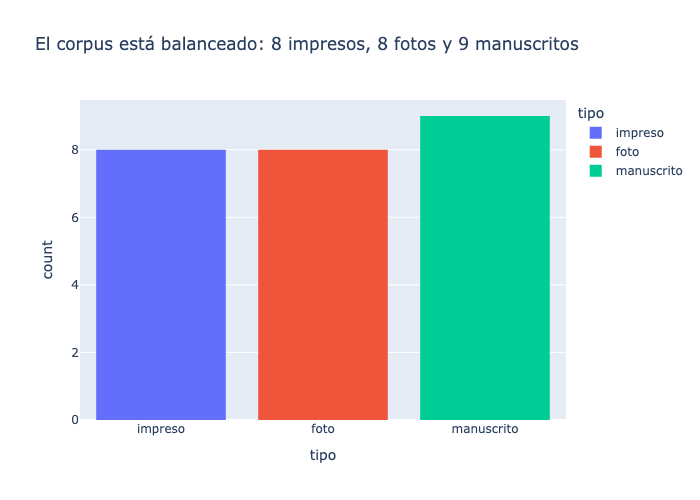

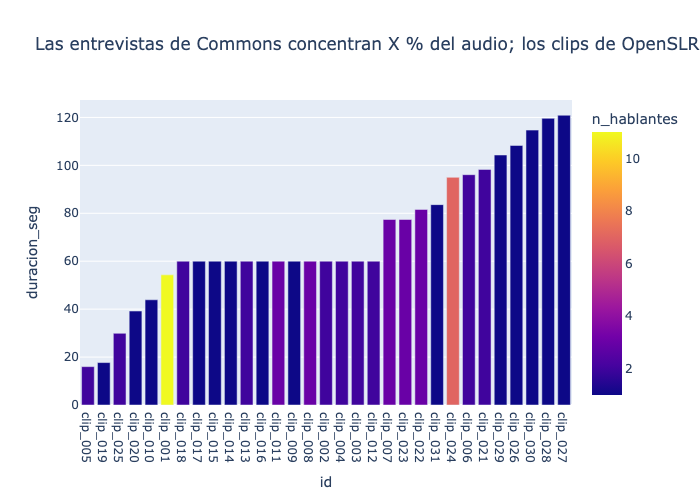

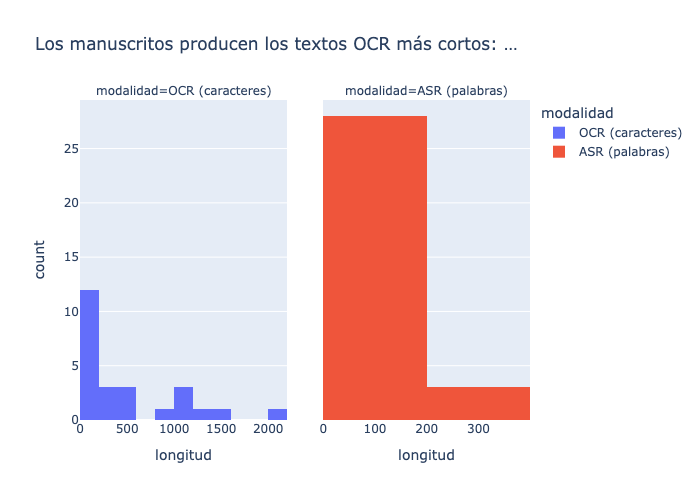

In [34]:
fig1 = px.histogram(documentos, x="tipo", color="tipo",
                    title="El corpus está balanceado: 8 impresos, 8 fotos y 9 manuscritos")
fig1.show()

fig2 = px.bar(transcripciones.sort_values("duracion_seg"), x="id", y="duracion_seg", color="n_hablantes",
              title="Las entrevistas de Commons concentran X % del audio; los clips de OpenSLR rondan 90 s")
fig2.show()

largos = pd.concat([
    documentos.assign(modalidad="OCR (caracteres)", longitud=documentos.texto_ocr.str.len()),
    transcripciones.assign(modalidad="ASR (palabras)", longitud=transcripciones.texto_asr.str.split().str.len()),
])
fig3 = px.histogram(largos, x="longitud", facet_col="modalidad", color="modalidad",
                    facet_col_spacing=0.08, title="Los manuscritos producen los textos OCR más cortos: …")
fig3.update_xaxes(matches=None)
fig3.show()

In [35]:
documentos["n_caracteres"] = documentos.texto_ocr.str.len()
display(documentos.nlargest(3, "n_caracteres")[["id", "tipo", "n_caracteres", "texto_ocr"]])
display(documentos.nsmallest(3, "n_caracteres")[["id", "tipo", "n_caracteres", "texto_ocr"]])
display(transcripciones.nlargest(3, "duracion_seg")[["id", "duracion_seg", "n_hablantes", "texto_asr"]])
display(transcripciones.nsmallest(3, "duracion_seg")[["id", "duracion_seg", "n_hablantes", "texto_asr"]])

,id,tipo,n_caracteres,texto_ocr
11,doc_012,foto,2020,Huaca Melgarejo uaca Melgarejo es un sitio arq...
23,doc_024,manuscrito,1435,BASTA A LA VIOLENCIA LA ViOlENCIA ¿Qué er la v...
5,doc_006,impreso,1269,"HIMNO DE CHANCHAMAYO CORO Chanchamayo, el “PER..."


,id,tipo,n_caracteres,texto_ocr
9,doc_010,foto,12,FOAED BEYTIA
8,doc_009,foto,16,ANCO DL HERRADOR
10,doc_011,foto,18,CALLE DE MELCHOMAL


,id,duracion_seg,n_hablantes,texto_asr
26,clip_027,120.9,1,¿Cuál es el periódico más importante? Los niño...
27,clip_028,119.6,1,¿Gano algún premio a esa película? El otro día...
29,clip_030,114.7,1,"Tocar el silófono es mi hobby favorito, el otr..."


,id,duracion_seg,n_hablantes,texto_asr
4,clip_005,16.0,2,[HABLANTE_1] Si quieres sentir pena por alguie...
18,clip_019,17.7,1,que mis hijos algún día ve los grandes y que l...
24,clip_025,29.9,2,"[HABLANTE_1] Normal, pero no resultaba, no es ..."


In [36]:
cols_doc = ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]
cols_aud = ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia"]
documentos["texto_referencia"] = ""        # se completa en la Parte 2
transcripciones["texto_referencia"] = ""

documentos[cols_doc].to_csv(DATOS / "documentos.csv", index=False)
transcripciones[cols_aud].to_csv(DATOS / "transcripciones.csv", index=False)

In [37]:
fuentes = pd.concat([
    inventario.assign(modalidad="documento", acceso="Descarga con descargar() desde Commons / foto propia (no publicada)"),
    audios.assign(modalidad="audio", acceso="Descarga de Commons (AUDIOS_COMMONS) / clips_openslr73() en 01_extraccion.ipynb"),
])[["id", "modalidad", "fuente_url", "licencia", "acceso"]]
fuentes.to_csv(DATOS / "fuentes.csv", index=False)

for nombre, df in [("documentos", documentos[cols_doc]), ("transcripciones", transcripciones[cols_aud]), ("fuentes", fuentes)]:
    print(nombre, df.shape)
display(documentos[cols_doc].head()); display(transcripciones[cols_aud].head())

documentos (25, 7)
transcripciones (31, 8)
fuentes (56, 5)


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,https://commons.wikimedia.org/?curid=2121996 (...,302 La Compañia) Fomiento del Per N1062350 deO...,"PaddleOCR 3.7.0 PP-OCRv6 (engine=transformers,...",
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,https://commons.wikimedia.org/?curid=2229021 (...,Serie eS UOnAh H N9 291035 N9291035 La Conprañ...,"PaddleOCR 3.7.0 PP-OCRv6 (engine=transformers,...",
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,https://commons.wikimedia.org/?curid=2263189 (...,188 2 TMC El Banco del Peru Sagara CIEN PESOS ...,"PaddleOCR 3.7.0 PP-OCRv6 (engine=transformers,...",
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,https://commons.wikimedia.org/?curid=2044186 (...,Banco Arequipa 15824 40 CENTAVOS 1 I Sagaráala...,"PaddleOCR 3.7.0 PP-OCRv6 (engine=transformers,...",
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,https://commons.wikimedia.org/?curid=2284104 (...,LA DEL REPÚBLICA PERU en uonedade oro Al sapre...,"PaddleOCR 3.7.0 PP-OCRv6 (engine=transformers,...",


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.ogg,54.3,es,"[HABLANTE_1] Sí, déjalo ya, así está la banda....","faster-whisper small (int8, CPU, VAD on, beam=5)",11,
1,clip_002,datos/raw/audio/clip_002.wav,60.0,es,"[HABLANTE_1] Buenas noches, primeramente es mi...","faster-whisper small (int8, CPU, VAD on, beam=5)",2,
2,clip_003,datos/raw/audio/clip_003.wav,60.0,es,[HABLANTE_1] país es la enseñanza que nos da c...,"faster-whisper small (int8, CPU, VAD on, beam=5)",2,
3,clip_004,datos/raw/audio/clip_004.wav,60.0,es,[HABLANTE_1] tenga un comportamiento positivo ...,"faster-whisper small (int8, CPU, VAD on, beam=5)",2,
4,clip_005,datos/raw/audio/clip_005.wav,16.0,es,[HABLANTE_1] Si quieres sentir pena por alguie...,"faster-whisper small (int8, CPU, VAD on, beam=5)",2,


### Ejemplos publicables para la app
Tres imágenes de Commons sin datos personales (dominio público y CC0/CC BY-SA) y dos clips de OpenSLR 73 (CC BY-SA 4.0, lectores anónimos), reducidos para publicarse en `datos/ejemplos/`.

In [38]:
# Ejemplos publicables para la app (P3.2): 3 imágenes de Commons sin datos personales y 2 clips de OpenSLR 73
EJ = DATOS / "ejemplos"; EJ.mkdir(exist_ok=True)
for i in ["doc_001", "doc_009", "doc_013"]:   # billete de 1 sol, letrero de calle, cartel de rutas
    img = Image.open(documentos.set_index("id").archivo[i]); img.thumbnail((1000, 1000))
    img.convert("RGB").save(EJ / f"{i}.jpg", quality=85)
for i in ["clip_029", "clip_030"]:            # clips de OpenSLR 73 (CC BY-SA 4.0, lectores anónimos)
    sf.write(EJ / f"{i}.ogg", cargar_audio(transcripciones.set_index("id").archivo_audio[i]), SR,
             format="OGG", subtype="VORBIS")
sorted(p.name for p in EJ.iterdir())

['clip_029.ogg', 'clip_030.ogg', 'doc_001.jpg', 'doc_009.jpg', 'doc_013.jpg']